# Bài toán 3 — Phân tích sai số và độ nhạy
## 8. Phân tích lỗi và độ nhạy
Giữ nguyên mốc phát triển 04/07/2012–01/07/2021; ba lượt validation 548 ngày; đánh giá hồi cứu 02/07/2021–31/12/2022 (548 ngày). Phân tích sai số của mô hình chính Hybrid Ensemble và đóng góp của từng thành phần. Dùng mùa vụ mức gốc cố định có hiệu ứng thứ làm đối chứng trực tiếp. Test không hoàn toàn độc lập với quá trình nghiên cứu kiến trúc trước đây.
### 8.1. Sai số từng ngày
Sai số có dấu = dự báo − thực tế. Âm nghĩa là dự báo thấp. Đơn vị MAE/RMSE: triệu đơn vị tiền tệ; R² không có đơn vị.

In [22]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sales_path = Path("data/raw/sales.csv")
start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
project_root = next(
    (folder for folder in (start, *start.parents) if (folder / sales_path).is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Không tìm thấy data/raw/sales.csv. Hãy đặt notebook trong dự án "
        "hoặc trỏ RETAIL_ANALYTICS_ROOT về thư mục gốc."
    )

prediction_path = project_root / "data/model/du_bao/forecast_predictions.csv"
if not prediction_path.is_file():
    raise FileNotFoundError("Chạy 02_mo_hinh.ipynb để tạo forecast_predictions.csv.")

predictions = pd.read_csv(
    prediction_path, parse_dates=["Date", "TrainEnd"], float_precision="round_trip",
)
targets = ["Revenue", "COGS"]

observed = pd.read_csv(
    project_root / sales_path, usecols=["Date", *targets], parse_dates=["Date"],
).set_index("Date").sort_index()[targets]
if not observed.index.is_unique:
    raise ValueError("sales.csv có ngày trùng. Kiểm tra lại ở 01_du_lieu.ipynb.")

contest_name = "Baseline cuộc thi"
fixed_name = "Mùa vụ, mức gốc cố định"


def prediction_frame(rows):
    return rows.set_index("Date")[targets].sort_index()


def test_forecast_for(method):
    return prediction_frame(predictions.loc[
        predictions["Split"].eq("test") & predictions["Method"].eq(method)
    ])

from io import BytesIO
from IPython.display import Image

to_millions = 1_000_000


weekday_name = "Mùa vụ mức gốc cố định + hiệu ứng thứ"
hybrid_name = "Hybrid Ensemble phân rã và phân khúc"
hybrid_test_forecast = test_forecast_for(hybrid_name)
weekday_test_forecast = test_forecast_for(weekday_name)
final_dates = hybrid_test_forecast.index
test_actual = observed.loc[final_dates]
assert final_dates.equals(pd.date_range('2021-07-02','2022-12-31',name='Date'))
assert weekday_test_forecast.index.equals(final_dates)
assert not predictions.duplicated(['Split','Fold','Method','Date']).any()
assert predictions.groupby(['Split','Fold','Method']).size().eq(548).all()
assert (predictions.Date > predictions.TrainEnd).all()
assert predictions.loc[predictions.Split.eq('validation'),'Date'].max() <= pd.Timestamp('2021-07-01')


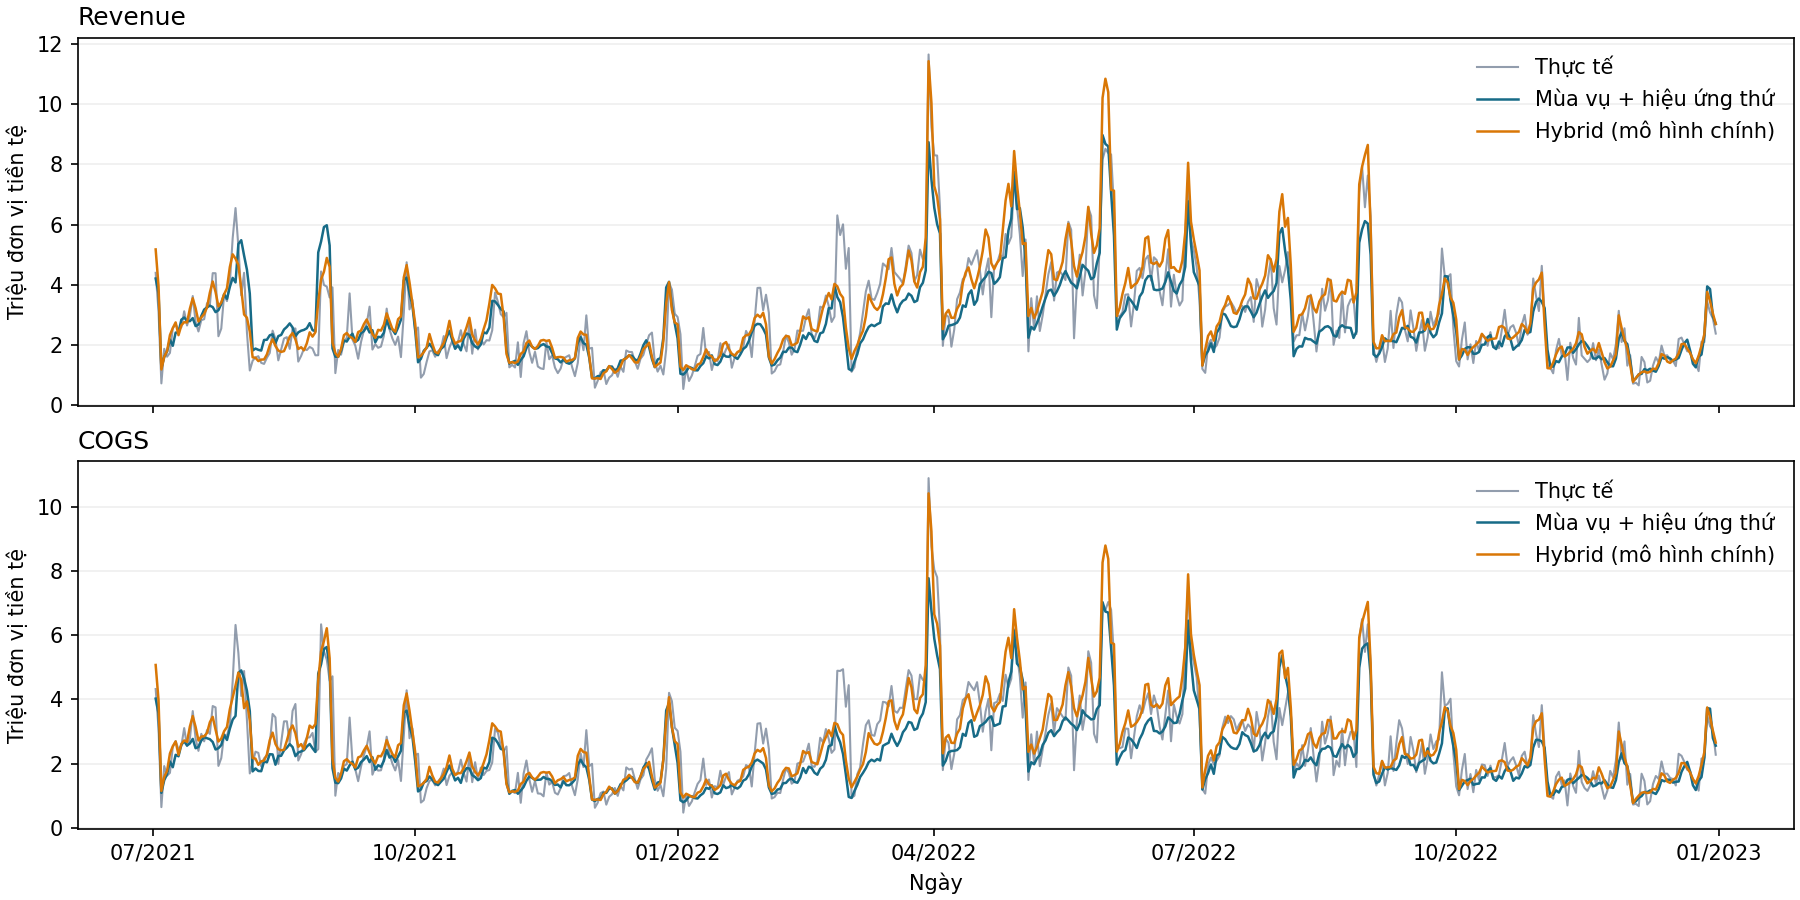

Revenue — Hybrid: 5 ngày lệch nhiều nhất (triệu đơn vị tiền tệ)


,Thực tế,Dự báo,Sai số có dấu,Sai số tuyệt đối
Date,,,,
2022-03-02,5.222,1.891,-3.331,3.331
2022-08-01,4.082,7.008,2.926,2.926
2022-02-28,6.007,3.574,-2.433,2.433
2022-05-20,2.227,4.625,2.399,2.399
2022-02-26,6.305,3.950,-2.355,2.355


COGS — Hybrid: 5 ngày lệch nhiều nhất (triệu đơn vị tiền tệ)


,Thực tế,Dự báo,Sai số có dấu,Sai số tuyệt đối
Date,,,,
2022-03-02,4.446,1.538,-2.909,2.909
2021-09-02,4.722,2.155,-2.567,2.567
2022-08-01,3.201,5.522,2.321,2.321
2021-08-28,2.453,4.609,2.156,2.156
2022-02-28,4.943,2.894,-2.049,2.049


In [23]:
from matplotlib import dates as mdates

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, layout="constrained")
for ax, target in zip(axes, targets):
    ax.plot(final_dates, test_actual[target] / to_millions, label="Thực tế",
            color="#64748B", alpha=0.7, linewidth=1.0)
    ax.plot(final_dates, weekday_test_forecast[target] / to_millions, label="Mùa vụ + hiệu ứng thứ",
            color="#176B87", linewidth=1.2)
    ax.plot(final_dates, hybrid_test_forecast[target] / to_millions, label="Hybrid (mô hình chính)", color="#D97706", linewidth=1.2)
    ax.set_title(target, loc="left")
    ax.set_ylabel("Triệu đơn vị tiền tệ")
    ax.grid(axis="y", alpha=0.2)
    ax.legend(loc="upper right", frameon=False)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
axes[-1].set_xlabel("Ngày")
with BytesIO() as buffer:
    fig.savefig(buffer, format="png", dpi=150)
    display(Image(data=buffer.getvalue(), width=950))
plt.close(fig)

daily_errors = {}
for target in targets:
    errors = pd.DataFrame({
        "Thực tế": test_actual[target],
        "Dự báo": hybrid_test_forecast[target],
    })
    errors["Sai số có dấu"] = errors["Dự báo"] - errors["Thực tế"]
    errors["Sai số tuyệt đối"] = errors["Sai số có dấu"].abs()
    daily_errors[target] = errors
    print(f"{target} — Hybrid: 5 ngày lệch nhiều nhất (triệu đơn vị tiền tệ)")
    display((errors.nlargest(5, "Sai số tuyệt đối") / to_millions).round(3))

,Chỉ tiêu,Revenue,COGS,Revenue,COGS
,Phương pháp,Mùa vụ mức gốc cố định + hiệu ứng thứ,Mùa vụ mức gốc cố định + hiệu ứng thứ,Hybrid Ensemble phân rã và phân khúc,Hybrid Ensemble phân rã và phân khúc
Tháng,Số ngày,,,,
2021-07,30,0.461,0.477,0.412,0.405
2021-08,31,0.881,0.627,0.414,0.548
2021-09,30,0.496,0.428,0.526,0.477
2021-10,31,0.353,0.293,0.457,0.344
2021-11,30,0.404,0.321,0.428,0.351
2021-12,31,0.376,0.383,0.324,0.348
2022-01,31,0.431,0.444,0.342,0.309
2022-02,28,0.723,0.641,0.589,0.479


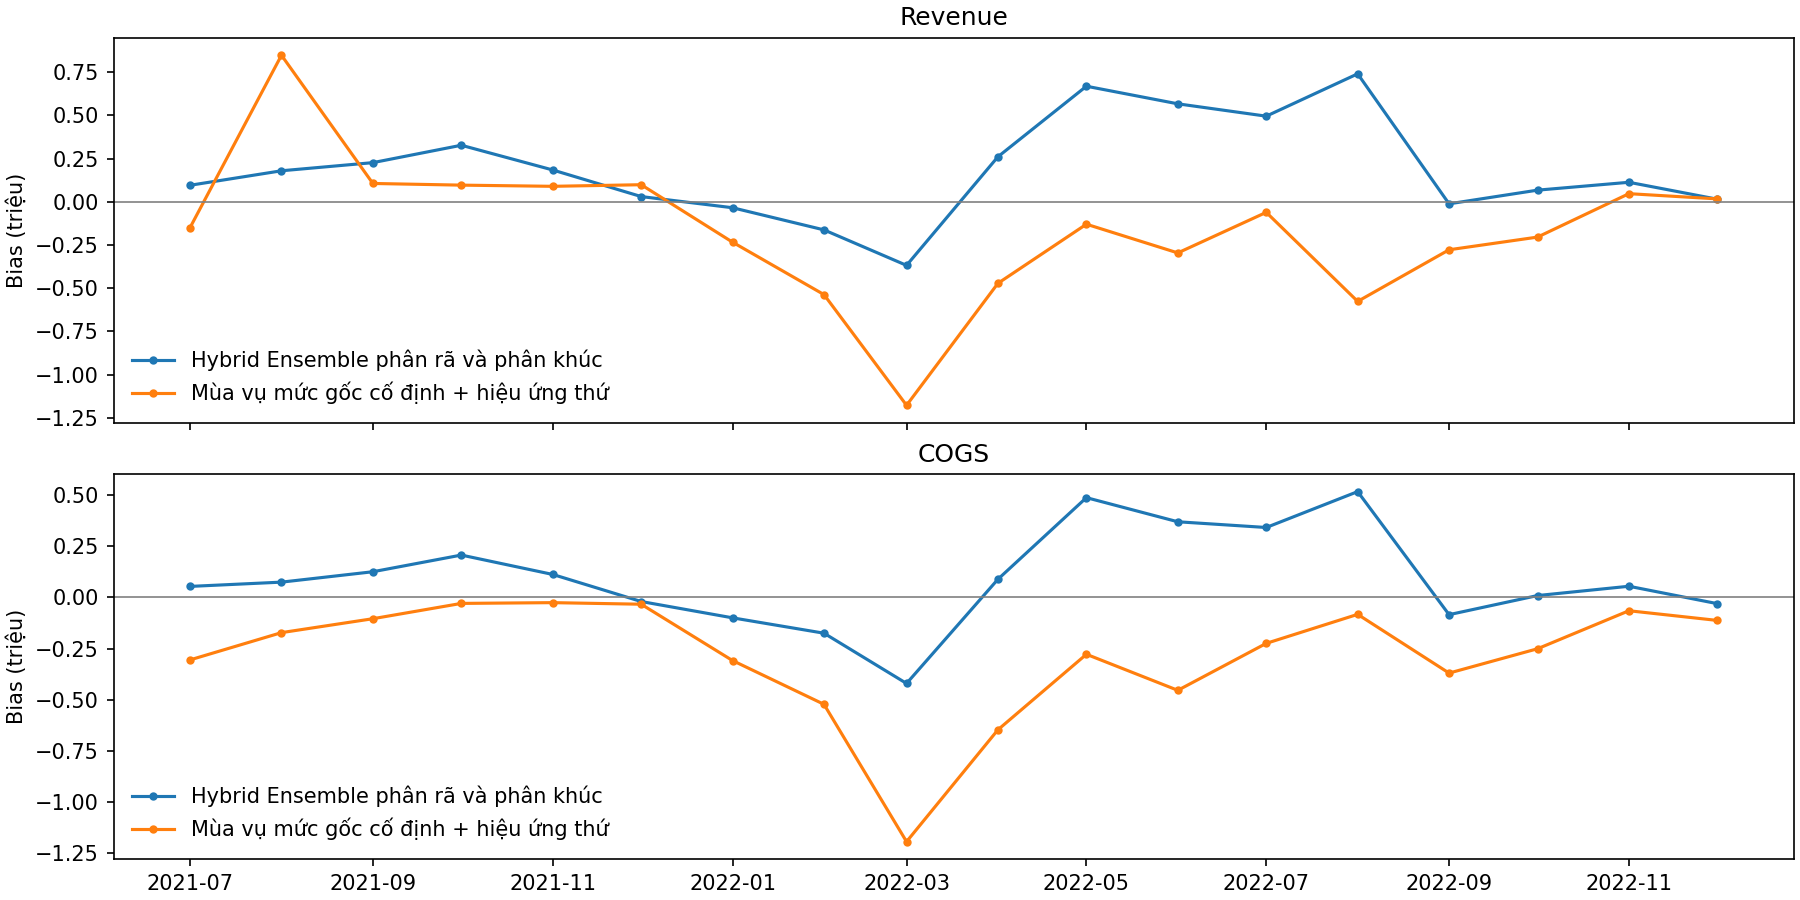

In [24]:
error_rows=[]
for method, forecast in [(weekday_name, weekday_test_forecast), (hybrid_name, hybrid_test_forecast)]:
    for target in targets:
        error=(forecast[target]-test_actual[target])/to_millions
        for month,g in error.groupby(error.index.to_period('M')):
            error_rows.append({'Tháng':str(month),'Phương pháp':method,'Chỉ tiêu':target,'Bias':g.mean(),'MAE':g.abs().mean(),'Số ngày':len(g)})
monthly_errors=pd.DataFrame(error_rows)
display(monthly_errors.pivot(index=['Tháng','Số ngày'],columns=['Chỉ tiêu','Phương pháp'],values='MAE').round(3))
fig,axes=plt.subplots(2,1,figsize=(12,6),sharex=True,layout='constrained')
for ax,target in zip(axes,targets):
    for label,g in monthly_errors.loc[monthly_errors['Chỉ tiêu'].eq(target)].groupby('Phương pháp'):
        ax.plot(pd.to_datetime(g['Tháng']),g['Bias'],marker='o',markersize=3,label=label)
    ax.axhline(0,color='gray',linewidth=.8);ax.set_title(target);ax.set_ylabel('Bias (triệu)');ax.legend(frameon=False)
with BytesIO() as buffer:
    fig.savefig(buffer, format="png", dpi=150)
    display(Image(data=buffer.getvalue(), width=950))
plt.close(fig)


### 8.2. Độ nhạy theo độ dài dự báo và cửa sổ trung bình
So sánh Hybrid và các đối chứng trên 28, 182, 365 và 548 ngày đầu của cùng dự báo. Kiểm tra thêm độ nhạy của mô hình trung bình với các cửa sổ 14, 28 và 56 ngày. Các so sánh trong mục này chỉ dùng validation.

In [25]:
def evaluate(actual, forecast):
    pd.testing.assert_index_equal(actual.index, forecast.index)
    pd.testing.assert_index_equal(actual.columns, forecast.columns)
    if not np.isfinite(forecast.to_numpy(dtype=float)).all():
        raise ValueError("Dự báo có giá trị thiếu hoặc không hữu hạn.")
    actual = actual.astype(float) / 1_000_000
    error = forecast.astype(float) / 1_000_000 - actual
    squared_error = error.pow(2)
    variation = (actual - actual.mean()).pow(2).sum()
    return pd.DataFrame({
        "MAE": error.abs().mean(),
        "RMSE": np.sqrt(squared_error.mean()),
        "R²": 1 - squared_error.sum() / variation.where(variation > 0),
    }).rename_axis("Chỉ tiêu")


def repeat_level(level, dates):
    return pd.DataFrame(
        np.tile(level.to_numpy(dtype=float), (len(dates), 1)),
        index=dates, columns=level.index,
    )

validation_predictions = {}
validation_actual = {}
train_ends = {}
score_rows = []

validation = predictions.loc[predictions["Split"].eq("validation")]
for (fold_id, method), rows in validation.groupby(["Fold", "Method"], sort=False):
    forecast = prediction_frame(rows)
    actual = observed.loc[forecast.index]
    validation_predictions[fold_id, method] = forecast
    validation_actual[fold_id] = actual
    train_ends[fold_id] = rows["TrainEnd"].iloc[0]
    score_rows.append(evaluate(actual, forecast).assign(Fold=fold_id, Method=method))

validation_scores = pd.concat(score_rows).reset_index().rename(columns={"Method": "Phương pháp"})


comparison_methods = [contest_name, fixed_name, weekday_name, hybrid_name]
if not set(comparison_methods).issubset(validation["Method"]):
    raise ValueError("Chạy lại 02_mo_hinh.ipynb để tạo đủ dự báo Hybrid và các đối chứng.")
by_fold = validation_scores.loc[validation_scores["Phương pháp"].isin(comparison_methods)]
display(by_fold.pivot(index="Fold", columns=["Phương pháp", "Chỉ tiêu"], values="MAE").round(3))

horizon_rows = []
for length in (28, 182, 365, 548):
    for fold_id, actual in validation_actual.items():
        for name in comparison_methods:
            forecast = validation_predictions[fold_id, name]
            score = evaluate(actual.iloc[:length], forecast.iloc[:length])
            horizon_rows.append(score.assign(Số_ngày=length, Phương_pháp=name))
horizon_scores = pd.concat(horizon_rows).reset_index()
display(
    horizon_scores.pivot_table(index="Số_ngày", columns=["Phương_pháp", "Chỉ tiêu"], values="MAE")
    .rename_axis(index="Số ngày dự báo", columns=["Phương pháp", "Chỉ tiêu"])
    .round(3)
)

window_rows = []
for width in (14, 28, 56):
    for fold_id, train_end in train_ends.items():
        train = observed.loc[:train_end, targets]
        actual = validation_actual[fold_id]
        score = evaluate(actual, repeat_level(train.tail(width).mean(), actual.index))
        window_rows.append(score.assign(Cửa_sổ=width, Fold=fold_id))
window_scores = pd.concat(window_rows).reset_index()
display(window_scores.pivot_table(index="Cửa_sổ", columns="Chỉ tiêu", values="MAE").round(3))

Phương pháp Baseline cuộc thi        Mùa vụ, mức gốc cố định         \
Chỉ tiêu              Revenue   COGS                 Revenue   COGS   
Fold                                                                  
1                       1.454  1.216                   1.180  0.967   
2                       2.070  1.876                   1.797  1.615   
3                       0.601  0.493                   0.659  0.562   

Phương pháp Mùa vụ mức gốc cố định + hiệu ứng thứ         \
Chỉ tiêu                                  Revenue   COGS   
Fold                                                       
1                                           1.105  0.904   
2                                           1.791  1.598   
3                                           0.649  0.553   

Phương pháp Hybrid Ensemble phân rã và phân khúc         
Chỉ tiêu                                 Revenue   COGS  
Fold                                                     
1                                          0.912  0.797  
2                                          2.457  2.149  
3                                          0.526  0.449

Phương pháp    Baseline cuộc thi         Hybrid Ensemble phân rã và phân khúc  \
Chỉ tiêu                    COGS Revenue                                 COGS   
Số ngày dự báo                                                                  
28                         0.601   0.676                                0.492   
182                        0.939   1.053                                0.872   
365                        1.099   1.274                                1.042   
548                        1.195   1.375                                1.131   

Phương pháp            Mùa vụ mức gốc cố định + hiệu ứng thứ          \
Chỉ tiêu       Revenue                                  COGS Revenue   
Số ngày dự báo                                                         
28               0.573                                 0.504   0.577   
182              1.016                                 0.869   1.001   
365              1.222                                 0.963   1.121   
548              1.299                                 1.018   1.182   

Phương pháp    Mùa vụ, mức gốc cố định          
Chỉ tiêu                          COGS Revenue  
Số ngày dự báo                                  
28                               0.549   0.621  
182                              0.910   1.035  
365                              0.984   1.138  
548                              1.048   1.212

Chỉ tiêu,COGS,Revenue
Cửa_sổ,,
14,2.881,3.338
28,2.504,3.091
56,2.607,3.275


### 8.3. Thực nghiệm loại bỏ thành phần (Ablation Study)
Các biến thể sau là thí nghiệm chẩn đoán, không phải các mô hình chính bổ sung vào bảng 11 mô hình.

- Bỏ CatBoost: chuẩn hóa lại trọng số 65:20 của hai nhánh còn lại.
- Bỏ Recovery Gate: bỏ hiệu chỉnh phục hồi có điều kiện, giữ các cơ chế xu hướng trong mô hình thành phần.
- Bỏ hiệu chỉnh ngoài mẫu: tắt cả hiệu chỉnh cuối tháng, lịch và shape ngoài mẫu.
- Bỏ nhánh xu hướng giảm dần: bỏ riêng nhánh Ridge dài hạn bổ sung.
- Bỏ nhánh chu kỳ hai năm: bỏ nhánh Ridge + Fourier bổ sung, không loại mọi đặc trưng chẵn/lẻ.
- Bỏ nhánh phân khúc: bỏ nhánh dự báo tám phân khúc cuối, giữ các đặc trưng phân khúc trong mô hình nền.

Mỗi biến thể có lịch sử dự báo ngoài mẫu riêng. Khi chạy lượt tiếp theo, chỉ thêm nhãn của lượt đã kết thúc. Không thay tham số và không ghi đè dự báo chính. Các hàm huấn luyện bên dưới sao lại từ notebook 02 để chạy độc lập với kernel khác.

In [26]:
dev_start=pd.Timestamp('2012-07-04'); dev_end=pd.Timestamp('2021-07-01')
sales_dev=observed.loc[dev_start:dev_end].copy()
assert len(sales_dev)==3285
horizon=548
from scipy.ndimage import gaussian_filter1d
from scipy.sparse import hstack
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import PoissonRegressor, Ridge
from sklearn.preprocessing import OneHotEncoder
from threadpoolctl import threadpool_limits
from catboost import CatBoostRegressor

TARGETS = targets

def read_raw(name, **kwargs):
    return pd.read_csv(project_root / "data/raw" / name, **kwargs)

orders = read_raw("orders.csv", usecols=["order_id", "order_date"], parse_dates=["order_date"])
orders = orders.loc[orders.order_date.between(dev_start, dev_end)]
items = read_raw("order_items.csv", usecols=["order_id", "product_id", "quantity", "unit_price"])
products = read_raw("products.csv", usecols=["product_id", "segment", "price", "cogs"])
assert orders.order_id.is_unique and products.product_id.is_unique
items = items.loc[items.order_id.isin(orders.order_id)]
lines = items.merge(orders, on="order_id", validate="many_to_one").merge(products, on="product_id", validate="many_to_one")
assert len(lines) == len(items)
lines["Revenue"] = lines.quantity * lines.unit_price
lines["COGS"] = lines.quantity * lines.cogs
lines = lines.assign(base=lines.price, actual=lines.unit_price, cost=lines.cogs, N=1, revenue=lines.Revenue)
daily = lines.groupby("order_date").agg(lines=("quantity", "size"), quantity=("quantity", "mean"), price=("price", "mean"), cost=("cogs", "mean"), actual_price=("unit_price", "mean"), Revenue=("Revenue", "sum"), COGS=("COGS", "sum"))
daily["price_factor"] = daily.actual_price / daily.price
assert daily.index.equals(sales_dev.index)
np.testing.assert_allclose(daily[TARGETS], sales_dev[TARGETS], atol=.011, rtol=0)
daily[TARGETS] = sales_dev[TARGETS].to_numpy()
panel = lines.groupby(["order_date", "segment"])[["base", "actual", "cost", "N", "quantity", "revenue"]].sum().unstack(fill_value=0)
seg_daily = lines.groupby(["order_date", "segment"])[["N", "Revenue", "COGS"]].sum().rename(columns={"N":"lines"}).unstack(fill_value=0)
assert panel.index.equals(daily.index) and seg_daily.index.equals(daily.index)
assert len(panel["N"].columns) == 8
np.testing.assert_allclose(seg_daily["Revenue"].sum(axis=1), daily.Revenue, atol=.011, rtol=0)
np.testing.assert_allclose(seg_daily["COGS"].sum(axis=1), daily.COGS, atol=.011, rtol=0)
print(f"Đối soát {len(daily):,} ngày, {len(lines):,} dòng hàng, {len(panel['N'].columns)} phân khúc.")
del orders, items, products, lines

def complete_months(frame, how="mean"):
    grouped = frame.resample("MS")
    result = getattr(grouped, how)()
    count = grouped.size()
    return result.loc[count == count.index.days_in_month]


Đối soát 3,285 ngày, 661,176 dòng hàng, 8 phân khúc.


In [27]:
def design(dates, training_size):
    """Hiệu ứng lịch có co rút. Xu hướng chậm được ước tính riêng."""
    month = dates.month.to_numpy()
    day = dates.day.to_numpy()
    week = dates.dayofweek.to_numpy()
    end = dates.days_in_month.to_numpy() - day
    odd = dates.year.to_numpy() % 2
    key = month * 100 + day
    md_phase = np.where(day < 9, day, np.where(end < 8, -1 - end, 0))
    blocks = []
    def add(weight, *features):
        frame = np.column_stack(features)
        # Mỗi tổ hợp lịch tương ứng với một biến chỉ báo.
        tokens = pd.DataFrame(frame).astype(str).agg("|".join, axis=1).to_numpy()[:, None]
        encoder = OneHotEncoder(handle_unknown="ignore")
        encoder.fit(tokens[:training_size])
        blocks.append(encoder.transform(tokens) * weight)
    add(2, month)
    add(2, day)
    add(2, end)
    add(2, week)
    add(1, month, odd)
    add(.9, month, md_phase)
    add(.65, key)
    add(.48, key, odd)
    add(.4, week, md_phase)
    add(.4, month, week)
    year_phase = dates.year.to_numpy() % 4
    add(.85, month, week, year_phase)
    add(.65, (month - 1) // 3, week, year_phase)
    add(.4, week, year_phase)
    add(.6, month, md_phase, odd)
    add(.35, month, dates.is_leap_year)
    # Cho phép mùa vụ gần đây khác những năm đầu dữ liệu.
    add(.3, dates.year >= 2019, month)
    return hstack(blocks, format="csr")

In [28]:
def forecast_lines(past, dates):
    n = len(past)
    calendar = past.index.append(dates)
    indicators = design(calendar, n)
    month = calendar.month.to_numpy()
    day = calendar.day.to_numpy()
    tree_features = np.column_stack([
        month, day, calendar.days_in_month - day, calendar.dayofweek,
        calendar.year % 2, calendar.year % 4, month * 32 + day,
        calendar.is_leap_year, (month - 1) // 3, calendar.dayofyear
    ])
    y = past.lines.to_numpy()
    weights = .5 ** ((n - 1 - np.arange(n)) / (365.25 * 4))
    weights[past.index.year < 2013] = 0
    annual_mean = past.lines.groupby(past.index.year).transform("mean").to_numpy()
    year_size = past.lines.groupby(past.index.year).transform("size")
    first_pass_weights = weights * (year_size.to_numpy() == np.where(past.index.is_leap_year, 366, 365))
    first_pass = PoissonRegressor(alpha=.0006, max_iter=600, tol=3e-6)
    first_pass.fit(indicators[:n], y / annual_mean, sample_weight=first_pass_weights)
    adjusted = y / first_pass.predict(indicators[:n])
    level = gaussian_filter1d(adjusted, sigma=65, mode="nearest", truncate=3)
    level[:90] = np.mean(adjusted[:140])
    level[-50:] = np.mean(adjusted[-105:])
    relative_volume = y / level

    glm = PoissonRegressor(alpha=.00038, max_iter=600, tol=3e-6)
    glm.fit(indicators[:n], relative_volume, sample_weight=weights)
    tree = HistGradientBoostingRegressor(loss="poisson", learning_rate=.06, max_iter=240,
             max_leaf_nodes=26, min_samples_leaf=15, l2_regularization=1, random_state=42)
    tree.fit(tree_features[:n], relative_volume, sample_weight=weights)
    shape = .65 * glm.predict(indicators) + .35 * tree.predict(tree_features)

    historical_ratio = pd.Series(relative_volume / shape[:n], index=past.index).clip(.3, 3.)
    monthly = complete_months(historical_ratio).tail(36)
    by_month = monthly.groupby(monthly.index.month).mean().to_numpy()
    by_month /= by_month.mean()
    smoothed = .25*np.roll(by_month, 1) + .5*by_month + .25*np.roll(by_month, -1)
    recent_shape = shape * (1 + .7 * (smoothed[month-1] - 1))

    def project(profile, use_recent_months):
        weekly = (y / profile[:n])[-728:].reshape(-1, 7).mean(axis=1)
        recent = np.average(weekly[-26:], weights=np.arange(1, 27))
        prior = np.average(weekly[-78:-52], weights=np.arange(1, 27))
        latest = weekly[-9:].mean()
        annual_change = np.clip(np.log(recent / prior), -.30, .30)
        half_year_change = np.clip(2*np.log(latest / weekly[-35:-26].mean()), -.30, .30)
        rate = .6*annual_change + .4*half_year_change
        if use_recent_months:
            latest = np.average(weekly[-16:], weights=np.arange(1, 17))
            rate *= .8
        horizon = np.arange(1, len(dates)+1) / 365.25
        return profile[n:] * latest * np.exp(rate * (1 - np.exp(-horizon)))

    return (project(shape, False) + project(recent_shape, True)) / 2

In [29]:
def forecast_prices(past, dates):
    idx = past.index.append(dates)
    n = len(past)
    time = (idx - idx[n - 1]).days.to_numpy() / 365.25
    columns = [time]
    for key, scale in [(idx.month, 1.), (idx.month*2 + idx.year%2, .65),
                        (idx.month*32 + idx.day, .22), (idx.day, .32),
                        (idx.dayofweek, .3), (idx.month*10 + np.minimum(9, idx.day//4), .5)]:
        columns.extend((pd.get_dummies(key).to_numpy(dtype=float)*scale).T)
    features = np.column_stack(columns)
    model = Ridge(alpha=1.4)
    target = np.log(past[["price","cost"]].to_numpy())
    model.fit(features[:n], target, sample_weight=.5**(-time[:n]/3.5))
    fitted = model.predict(features)
    residual = target - fitted[:n]
    correction = np.average(residual[-180:], axis=0, weights=np.arange(1,181))
    smear = np.mean(np.exp(residual[-365:]),axis=0) / np.exp(np.mean(residual[-365:],axis=0))
    return np.exp(fitted[n:] + correction) * smear

def forecast_components(past, dates):
    dates = pd.DatetimeIndex(dates)
    assert past.index.max() < dates.min()
    count = forecast_lines(past, dates)
    unit_values = forecast_prices(past, dates)
    ratio = past.price_factor.loc["2013":]
    typical = ratio.groupby([ratio.index.year%2, ratio.index.month, ratio.index.day]).median()
    requested = pd.MultiIndex.from_arrays([dates.year%2, dates.month, dates.day])
    unit_values[:, 0] *= typical.reindex(requested).fillna(1.).to_numpy()
    quantity = np.average(past.quantity, weights=past.lines)
    return pd.DataFrame(count[:,None] * quantity * unit_values, index=dates, columns=["Revenue","COGS"])

In [30]:
def curve(frame,dates,window,mode):
    monthly=complete_months(frame).tail(window)
    x=np.arange(len(monthly))/12
    end=x[-1]
    horizon=(dates.year-monthly.index[-1].year)*12+dates.month-monthly.index[-1].month
    future=end+horizon.to_numpy()/12
    def basis(t,m):
        mm=np.eye(12)[m-1]
        if mode=='spline':
            return np.column_stack([mm,t-end,.55*np.maximum(t-end+1.5,0)**2,.55*np.maximum(t-end+3.5,0)**2])
        period=float(mode)
        return np.column_stack([mm,t-end,np.sin(2*np.pi*t/period),np.cos(2*np.pi*t/period)])
    model=Ridge(alpha=.25)
    model.fit(basis(x,monthly.index.month),np.log(monthly.clip(lower=1.0)))
    log_future=model.predict(basis(future,dates.month))
    last=model.predict(basis(np.repeat(end,len(dates)),dates.month))
    change=np.clip(log_future-last,-.34*(future-end)[:,None],.34*(future-end)[:,None])
    return np.exp(last+change)

def monthly_forecast(panel,dates,old,window,mode):
    q=panel['quantity'].to_numpy().sum()/panel['N'].to_numpy().sum()
    ratio=panel['actual'].sum(axis=1)/panel['base'].sum(axis=1)
    ratio=ratio.loc['2013':]
    factors=ratio.groupby([ratio.index.year%2,ratio.index.month,ratio.index.day]).median()
    factor=factors.reindex(pd.MultiIndex.from_arrays([dates.year%2,dates.month,dates.day])).fillna(1).to_numpy()
    out=[]
    for k,values in enumerate(['base','cost']):
        gross=panel[values].copy()
        gross['TOTAL']=gross.sum(axis=1)
        monthly=curve(gross,dates,window,mode)
        avg=.5*monthly[:,-1]+.5*monthly[:,:-1].sum(axis=1)
        discount=factor if k==0 else np.ones(len(dates))
        old_nominal=old[:,k]/discount
        by_month=pd.Series(old_nominal,index=dates).groupby(dates.to_period('M')).transform('mean').to_numpy()
        years=dates.to_period('M')
        for period,size in years.value_counts().items():
            if size<15:
                same_month=years==period-12
                if same_month.any():
                    by_month[years==period]=old_nominal[same_month].mean()
        out.append(q*avg*old_nominal/by_month*discount)
    return np.column_stack(out)

In [31]:
def turning_forecast(panel,dates,base):
    m=complete_months(panel['base'].sum(axis=1)).to_numpy()
    def change(n,lag):
        k=len(m)-lag
        return np.log(m[k-n:k].mean()/m[k-n-12:k-12].mean())
    short=change(3,0)
    earlier=change(6,6)
    annual=change(12,0)
    # Tăng trọng số đường dài khi xu hướng gần đây củng cố tín hiệu của năm.
    same=short*annual>0
    acceleration=(short-earlier)*np.sign(annual)
    trend_weight=.65*np.clip(acceleration/.18,0,1)*np.clip(abs(short)/.16,0,1) if same else 0.
    q=m[-24:].reshape(8,3).mean(axis=1)
    changes=np.log(q[-4:]/q[:4])
    consistency=np.mean(changes*np.sign(annual)>0)
    trend_weight*=np.clip(2*consistency-1,0,1)
    volume_month=complete_months(panel['N'].sum(axis=1)).to_numpy()
    vq=volume_month[-24:].reshape(8,3).mean(axis=1)
    volume_breadth=np.clip(2*np.mean(vq[4:]>vq[:4])-1,0,1)
    if annual>0:
        trend_weight*=volume_breadth
    spline=monthly_forecast(panel,dates,base,120,'spline')
    local=monthly_forecast(panel,dates,base,36,'7')
    # Phối hợp mô hình cơ sở với hai dự báo mức tháng.
    merged=(1-trend_weight)*base+trend_weight*spline
    result=.85*merged+.15*local
    # Hồi phục về mức dài hạn khi nhiều quý liên tiếp dịch chuyển cùng hướng.
    effects=[]
    for col in ['N','base']:
        month=complete_months(panel[col].sum(axis=1)).to_numpy()
        quarter=month[-24:].reshape(8,3).mean(axis=1)
        yoy=np.log(quarter[4:]/quarter[:4])
        gap=np.log(month[-96:-12].mean()/month[-12:].mean())
        signed=yoy*np.sign(gap)
        evidence=np.clip(signed.mean()/(2*max(.035,signed.std(ddof=1)/2)),0,1)
        breadth=np.clip(2*np.mean(signed>0)-1,0,1)
        effects.append(np.clip(gap,-1,1)*evidence*breadth)
    horizon=np.arange(1,len(dates)+1)/365.25
    effect=np.mean(effects)
    if effect>0:
        effect*=volume_breadth
    return result*np.exp(effect*(1-np.exp(-.75*horizon)))[:,None]

In [32]:
# Các hàm dự báo Ensemble chính — được dùng cả khi kiểm định và xuất file
from sklearn.preprocessing import OneHotEncoder
from scipy.sparse import hstack
def feat(idx):
 idx=pd.DatetimeIndex(idx); n=len(idx);m=idx.month.to_numpy();d=idx.day.to_numpy();dow=idx.dayofweek.to_numpy();e=idx.days_in_month.to_numpy()-d
 return pd.DataFrame(dict(month=m,day=d,dow=dow,end=e,quarter=idx.quarter,month_in_quarter=(m-1)%3,year_parity=idx.year%2,year_4=idx.year%4,dayofyear=idx.dayofyear,year=idx.year,month_day=m*32+d,
    is_wkend=(dow>=5).astype(int),week_in_month=((d-1)//7)+1,days_in_month=idx.days_in_month,
    is_month_start=(d==1).astype(int),is_month_end=(e==0).astype(int),
    day_sin=np.sin(2*np.pi*idx.dayofyear/365.25),day_cos=np.cos(2*np.pi*idx.dayofyear/365.25),
    dow_sin=np.sin(2*np.pi*dow/7),dow_cos=np.cos(2*np.pi*dow/7)))


def shape_cat(train,dates, iters=450,depth=5,history=8):
 # Data shape learned using only complete months.
 hist=train.loc[train.index >= train.index.max()-pd.DateOffset(years=history)].copy()
 groups=hist.index.to_period('M')
 valid=(pd.Series(np.ones(len(hist)),index=hist.index).groupby(groups).transform('size').to_numpy()==hist.index.days_in_month)
 hist=hist[valid];groups=hist.index.to_period('M')
 ratio=(hist/hist.groupby(groups).transform('mean')).clip(.07,9)
 X=feat(hist.index).drop(columns=['year']);Xt=feat(dates).drop(columns=['year']);out=[]
 wt=np.exp(-np.arange(len(hist))[::-1]/(365.25*5))
 for j,col in enumerate(['Revenue','COGS']):
  cb=CatBoostRegressor(iterations=iters,depth=depth,learning_rate=.045,loss_function='RMSE',l2_leaf_reg=8,
        random_seed=123,verbose=False,thread_count=2,allow_writing_files=False)
  cb.fit(X, np.log(ratio[col].to_numpy()),sample_weight=wt)
  out.append(np.exp(cb.predict(Xt)))
  del cb
 out=np.column_stack(out)
 # Normalize to preserve monthly means.
 m=pd.DataFrame(out,index=dates).groupby(dates.to_period('M')).transform('mean').to_numpy()
 return out/np.maximum(m,1e-8)


def pattern(train, dates, n=6):
    years = train.groupby(train.index.year).size()
    complete = [int(y) for y, count in years.items() if count == (366 if pd.Timestamp(f"{y}-01-01").is_leap_year else 365)]
    assert complete, "Không có năm lịch sử đầy đủ."
    d = train.loc[train.index.year.isin(complete[-n:])].copy()
    d = d / d.groupby(d.index.to_period('M')).transform('mean')
    key = dates.month.to_numpy()*100 + dates.day.to_numpy()
    key = np.where(key == 229, 228, key)
    profiles = [d.loc[d.index.year == yr].groupby(lambda x: x.month*100+x.day).mean().reindex(key).to_numpy() for yr in complete[-n:]]
    return np.mean(profiles, axis=0)

FACTOR_WEIGHT = 0.65
HISTORICAL_WEIGHT = 0.20
CATBOOST_WEIGHT = 0.15
assert abs(FACTOR_WEIGHT+HISTORICAL_WEIGHT+CATBOOST_WEIGHT-1)<1e-12

def blend_daily_shapes(past, dates, factor_prediction):
    dates = pd.DatetimeIndex(dates)
    assert past.index.max() < dates.min(), 'Có nguy cơ dùng dữ liệu tương lai'
    base = np.asarray(factor_prediction,dtype=float)
    m = pd.DataFrame(base,index=dates).groupby(dates.to_period('M')).transform('mean').to_numpy()
    hist_pattern = pattern(past,dates,n=6)
    ml_pattern = shape_cat(past,dates,iters=450,depth=5,history=8)
    pred = FACTOR_WEIGHT*base + m*(HISTORICAL_WEIGHT*hist_pattern + CATBOOST_WEIGHT*ml_pattern)
    return np.maximum(pred,1.)



In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from threadpoolctl import threadpool_limits

TARGETS = ['Revenue','COGS']

def recovery_adjustment(past, dates, raw_prediction, strength=0.50, tau=600):
    """Tổng quát hoá hàm Ensemble; strength=.50, tau=600 cho cùng kết quả với Ensemble."""
    dates=pd.DatetimeIndex(dates)
    assert past.index.max()<dates.min(), 'Không được dùng dữ liệu sau thời điểm dự báo'
    year_mean=past[TARGETS].groupby(past.index.year).mean()
    days=past.groupby(past.index.year).size()
    complete=year_mean.loc[days.loc[year_mean.index].to_numpy() == np.where(pd.to_datetime(year_mean.index.astype(str)+"-01-01").is_leap_year,366,365)]
    drop_year=int(complete.Revenue.pct_change().idxmin())
    drop=float(complete.Revenue.pct_change().loc[drop_year])
    if drop>=-0.25 or (dates.min().year-drop_year)>8:
        return np.asarray(raw_prediction).copy(), {'regime_detected':False,'drop':drop}
    anchor=complete.loc[drop_year-1, TARGETS].to_numpy(dtype=float)
    year_level=pd.DataFrame(raw_prediction,index=dates,columns=TARGETS).groupby(dates.year).transform('mean').to_numpy()
    w=strength*np.exp(-np.arange(len(dates))/float(tau))
    factor=1+w[:,None]*(anchor/np.maximum(year_level,1.)-1.)
    return np.maximum(np.asarray(raw_prediction)*factor,1.),{
        'regime_detected':True, 'drop_year':drop_year, 'anchor_year':drop_year-1,
        'strength':strength, 'tau':tau, 'anchor':anchor.tolist()}



In [34]:
def growth_gate(past):
    m = past[TARGETS].resample('MS').mean()
    counts = past.resample('MS').size()
    m = m.loc[counts == counts.index.days_in_month]
    yoy = m.Revenue.pct_change(12).dropna()
    assert len(yoy)>=12
    p6,p12 = float((yoy.tail(6)>0).mean()),float((yoy.tail(12)>0).mean())
    return (min(p6,p12) if min(p6,p12)>0.5 else 0.),p6,p12

def base_ensemble(hist,seg,dates):
    with threadpool_limits(limits=2):
        base=forecast_components(hist,dates).to_numpy()
        factor_prediction=turning_forecast(seg,dates,base)
        ensemble=blend_daily_shapes(hist[TARGETS],dates,factor_prediction)
        recovered,_=recovery_adjustment(hist,dates,ensemble,strength=.445,tau=600)
    gate,p6,p12=growth_gate(hist)
    return {'Ensemble':ensemble,'Recovered':recovered,'Gated':ensemble+gate*(recovered-ensemble)},gate,p6,p12

In [35]:
def month_end_residual(records, dates, pred, strength=.15):
    dates=pd.DatetimeIndex(dates); chunks=[]
    for rec in records:
        dd=pd.DatetimeIndex(rec['dates']); mask=(dd<dates[0]) & np.isfinite(rec['actual']).all(axis=1)
        dd=dd[mask]; a=rec['actual'][mask]; p=rec['ensemble'][mask]
        if not len(dd): continue
        grp=dd.to_period('M'); full=pd.Series(1,index=dd).groupby(grp).transform('size').to_numpy()==dd.days_in_month
        dd=dd[full];a=a[full];p=p[full]
        if not len(dd): continue
        grp=dd.to_period('M');a=a/pd.DataFrame(a).groupby(grp).transform('mean').to_numpy();p=p/pd.DataFrame(p).groupby(grp).transform('mean').to_numpy()
        chunks.append(pd.DataFrame(np.log(a/p),index=dd,columns=['Revenue','COGS']))
    if not chunks: return pred.copy()
    residual=pd.concat(chunks).groupby(level=0).mean(); end=residual.index.days_in_month-residual.index.day
    profile=residual.groupby(end).median();corr=profile.reindex(dates.days_in_month-dates.day).fillna(0).to_numpy();q=pred*np.exp(strength*np.clip(corr,-.3,.3));g=dates.to_period('M');q*=pd.DataFrame(pred).groupby(g).transform('sum').to_numpy()/pd.DataFrame(q).groupby(g).transform('sum').to_numpy();return q

In [36]:
def residual_data(records, origin):
 chunks=[]
 for r in records:
  d=pd.DatetimeIndex(r['dates']);mask=(d<origin)&np.isfinite(r['actual']).all(1);d=d[mask];a=r['actual'][mask];p=r['ensemble'][mask];g=d.to_period('M');full=pd.Series(1,index=d).groupby(g).transform('size').values==d.days_in_month;d=d[full];a=a[full];p=p[full];g=d.to_period('M');
  if not len(d):continue
  a=a/pd.DataFrame(a).groupby(g).transform('mean').values;p=p/pd.DataFrame(p).groupby(g).transform('mean').values
  chunks.append(pd.DataFrame(np.log(a/p),index=d,columns=TARGETS))
 return pd.concat(chunks).groupby(level=0).mean() if chunks else pd.DataFrame(columns=TARGETS,index=pd.DatetimeIndex([]))

def features(d):
 d=pd.DatetimeIndex(d);return pd.DataFrame({'month':d.month,'day':d.day,'end':d.days_in_month-d.day,'dow':d.dayofweek,'parity':d.year%2,'week':(d.day-1)//7,'quarter':d.quarter,'startbin':np.minimum(d.day,8),'endbin':np.minimum(d.days_in_month-d.day,8)},index=d)
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge
from scipy.sparse import hstack

def correction(records,d,p,combo,alpha,strength,decay=0):
 d=pd.DatetimeIndex(d);r=residual_data(records,d[0]);
 if len(r)<120:return p.copy()
 tr=features(r.index);te=features(d);X=[];Xt=[]
 for cols in combo:
  enc=OneHotEncoder(handle_unknown='ignore');a=tr[list(cols)].astype(str).agg('_'.join,axis=1).values[:,None];b=te[list(cols)].astype(str).agg('_'.join,axis=1).values[:,None];X.append(enc.fit_transform(a));Xt.append(enc.transform(b))
 w=np.exp(-(d[0]-r.index).days.values/decay) if decay else None
 model=Ridge(alpha=alpha,solver='lsqr').fit(hstack(X).tocsr(),r.values,sample_weight=w);c=model.predict(hstack(Xt).tocsr());q=p*np.exp(strength*np.clip(c,-.4,.4));g=d.to_period('M');q*=pd.DataFrame(p).groupby(g).transform('sum').values/pd.DataFrame(q).groupby(g).transform('sum').values;return q


def calendar_residual(records, dates, pred):
    return correction(records, dates, pred, [("day",), ("dow",)], alpha=10, strength=.2, decay=365)


In [37]:
def factor_model(hist, dates, window=36, damp=12, alpha=1, recent=24):
 m=hist[['lines','Revenue','COGS']].resample('MS').sum(); counts=hist.resample('MS').size();m=m.loc[counts==counts.index.days_in_month];m['Revenue']/=m.lines;m['COGS']/=m.lines;m['lines']/=m.index.days_in_month
 m=m.tail(window);t=np.arange(len(m))-len(m)+1
 d=pd.DatetimeIndex(dates);future=(d.year-m.index[-1].year)*12+d.month-m.index[-1].month
 def basis(idx,t):
  month=idx.month.to_numpy();aug=(month==8)*(idx.year%2*2-1);return np.column_stack([t/12,np.eye(12)[month-1],aug])
 x=basis(m.index,t); y=np.log(m.to_numpy()); w=.5**(-t/recent); reg=Ridge(alpha=alpha);reg.fit(x,y,sample_weight=w)
 ft=damp*(1-np.exp(-future.to_numpy()/damp)) if damp else future.to_numpy()
 raw=np.exp(reg.predict(basis(d,ft)))
 return raw[:,0,None]*raw[:,1:]
def level_ratio(hist,d,p,window,damp,alpha,recent,mode):
 a=factor_model(hist,d,window,damp,alpha,recent);g=d.to_period('M');b=pd.DataFrame(p).groupby(g).transform('mean').values
 for per in g.unique():
  mask=g==per
  if mask.sum()<per.days_in_month and (g==per-12).any():b[mask]=p[g==per-12].mean(0)
 if mode=='level':a=a/a.mean(0)*b.mean(0)
 return np.clip(np.log(a/b),-.7,.7)

def damped_factor_adjustment(hist,dates,p):
    # Fixed conservative blend of an independent factor forecast; preserve the baseline overall mean in the alternative monthly level.
    return p*np.exp(.2*level_ratio(hist,dates,p,60,12,.1,24,'level'))


In [38]:
def new_resid(records,d,p,cols,alpha,weight,mode,half):
 parts=[]
 for _,dd,pp,yy in records:
  mask=(dd<d[0])&np.isfinite(yy).all(1);dd=dd[mask];pp=pp[mask];yy=yy[mask];g=dd.to_period('M');valid=pd.Series(1,index=dd).groupby(g).transform('sum').values==dd.days_in_month;dd=dd[valid];pp=pp[valid];yy=yy[valid];g=dd.to_period('M')
  if not len(dd):continue
  if mode=='shape':
   pp=pp/pd.DataFrame(pp).groupby(g).transform('mean').values;yy=yy/pd.DataFrame(yy).groupby(g).transform('mean').values
  val=np.log(yy/pp);parts.append(pd.DataFrame(val,index=dd))
 if not parts:return p.copy()
 rr=pd.concat(parts).groupby(level=0).mean();
 if len(rr)<120:return p.copy()
 def feat(d):return pd.DataFrame({'m':d.month,'d':d.day,'e':d.days_in_month-d.day,'w':d.dayofweek,'p':d.year%2,'q':d.year%4,'n':d.days_in_month,'b':(d.day-1)//7,'y':d.year,'early':np.minimum(d.day,5),'late':np.minimum(d.days_in_month-d.day,5)})
 a=feat(rr.index);b=feat(d);xs=[];xt=[]
 for c in cols:
  enc=OneHotEncoder(handle_unknown='ignore');x=a[list(c)].astype(str).agg('_'.join,axis=1).values[:,None];xx=b[list(c)].astype(str).agg('_'.join,axis=1).values[:,None];xs.append(enc.fit_transform(x));xt.append(enc.transform(xx))
 w=.5**((d[0]-rr.index).days.to_numpy()/half) if half else None
 reg=Ridge(alpha=alpha,solver='lsqr').fit(hstack(xs).tocsr(),rr.values,sample_weight=w);c=reg.predict(hstack(xt).tocsr());q=p*np.exp(weight*np.clip(c,-.3,.3));g=d.to_period('M')
 if mode=='shape':q*=pd.DataFrame(p).groupby(g).transform('sum').values/pd.DataFrame(q).groupby(g).transform('sum').values
 return q


def oof_shape_adjustment(records, dates, pred):
    return new_resid(records, dates, pred, (("m",),("w",),("early",),("late",)), 20, .2, "shape", 730)


In [39]:
def monthly(hist):
 m=hist[['lines','Revenue','COGS']].resample('MS').sum();cnt=hist.resample('MS').size();m=m.loc[cnt==cnt.index.days_in_month];m['Revenue']/=m.lines;m['COGS']/=m.lines;m['lines']/=m.index.days_in_month;return m

def alternative(hist,d,window=60,alpha=2,half=36,damp=12,parity=1):
 m=monthly(hist).tail(window);t=np.arange(len(m))-len(m)+1;last=m.index[-1];hf=(d.year-last.year)*12+d.month-last.month;ft=damp*(1-np.exp(-hf/damp))
 def basis(idx,t):
  month=idx.month.to_numpy(); parityv=idx.year.to_numpy()%2*2-1; a=2*np.pi*(month-1)/12; seasonal=np.column_stack([np.sin(a),np.cos(a),np.sin(2*a),np.cos(2*a),np.sin(3*a),np.cos(3*a)]);return np.column_stack([t/12,np.eye(12)[month-1],parityv[:,None]*seasonal*parity,parityv*.5,(month==8)*parityv])
 reg=Ridge(alpha=alpha).fit(basis(m.index,t),np.log(m.values),sample_weight=.5**(-t/half));v=np.exp(reg.predict(basis(d,ft)));return v[:,0,None]*v[:,1:]

def apply_alt(h,d,p,a,w,mode):
 g=d.to_period('M');b=pd.DataFrame(p).groupby(g).transform('mean').values
 for per in g.unique():
  mask=g==per
  if mask.sum()<per.days_in_month and (g==per-12).any():b[mask]=p[g==per-12].mean(0)
 if mode=='level':a=a/a.mean(0)*b.mean(0)
 elif mode=='year':
  a=a.copy()
  for yy in np.unique(d.year):
   mask=d.year==yy;a[mask]=a[mask]/a[mask].mean(0)*b[mask].mean(0)
 return p*np.exp(w*np.clip(np.log(a/b),-.5,.5))


def biennial_adjustment(hist,d,p):
    return apply_alt(hist,d,p,alternative(hist,d,84,.3,48,24,.5),.15,'year')


In [40]:
def segment_alternative(h,d,segmonthly,window=84,alpha=2,half=48,damp=24):
 m=segmonthly.loc[segmonthly.index + pd.offsets.MonthEnd(0) <= h.index.max()].tail(window);t=np.arange(len(m))-len(m)+1;idx=m.index;f=(d.year-idx[-1].year)*12+d.month-idx[-1].month;ft=damp*(1-np.exp(-f/damp));
 def design(idx,t):
  mo=idx.month.to_numpy();pa=idx.year.to_numpy()%2*2-1;rad=2*np.pi*(mo-1)/12;sea=np.column_stack([np.sin(rad),np.cos(rad),np.sin(2*rad),np.cos(2*rad)]);return np.column_stack([t/12,np.eye(12)[mo-1],pa*.5,pa[:,None]*sea*.5,(mo==8)*pa])
 count=m['lines'].values;v=np.concatenate([count/idx.days_in_month.to_numpy()[:,None],m['Revenue'].values/count,m['COGS'].values/count],axis=1);reg=Ridge(alpha=alpha).fit(design(idx,t),np.log(v),sample_weight=.5**(-t/half));q=np.exp(reg.predict(design(d,ft)));k=count.shape[1];return np.column_stack([(q[:,:k]*q[:,k:2*k]).sum(1),(q[:,:k]*q[:,2*k:]).sum(1)])

def segment_adjustment(hist,d,p,segmonthly):
 return apply_alt(hist,d,p,segment_alternative(hist,d,segmonthly,84,.3,48,24),.3,'year')


#### 8.3.1. Chạy các biến thể theo thời gian
Thành phần chung được tính một lần tại mỗi origin. Bản đầy đủ phải khớp dự báo lưu từ notebook 02. Chênh lệch MAE = MAE khi bỏ thành phần − MAE đầy đủ; số dương nghĩa là thành phần có ích ở cửa sổ đó.

In [41]:
FULL='Hybrid đầy đủ'
variants=[FULL,'Bỏ CatBoost','Bỏ Recovery Gate','Bỏ hiệu chỉnh ngoài mẫu','Bỏ nhánh xu hướng giảm dần','Bỏ nhánh chu kỳ hai năm','Bỏ nhánh phân khúc']
states={v:{'records':[],'factor_records':[]} for v in variants}
abl_rows=[]; gate_rows=[]
def ablation_predict(train, dates):
    dates=pd.DatetimeIndex(dates); end=train.index.max(); origin=dates.min()
    hist=daily.loc[:end].copy(); seg=panel.loc[:end].copy()
    sm=complete_months(seg_daily.loc[:end],how='sum')
    assert hist.index.equals(train.index) and seg.index.equals(train.index)
    assert end+pd.Timedelta(days=1)==origin and (sm.index+pd.offsets.MonthEnd(0)<origin).all()
    with threadpool_limits(limits=2):
        base=forecast_components(hist,dates).to_numpy()
        fp=turning_forecast(seg,dates,base)
        ensemble=blend_daily_shapes(hist[TARGETS],dates,fp)
        m=pd.DataFrame(fp,index=dates).groupby(dates.to_period('M')).transform('mean').to_numpy()
        no_cat=np.maximum((FACTOR_WEIGHT*fp+HISTORICAL_WEIGHT*m*pattern(hist[TARGETS],dates,n=6))/(FACTOR_WEIGHT+HISTORICAL_WEIGHT),1.)
        gate,p6,p12=growth_gate(hist)
        out={}
        for v in variants:
            rr=states[v]['records']; fr=states[v]['factor_records']
            assert all(pd.DatetimeIndex(r['dates']).max()<origin for r in rr)
            assert all(pd.DatetimeIndex(r[1]).max()<origin for r in fr)
            ens=no_cat if v=='Bỏ CatBoost' else ensemble
            rec,_=recovery_adjustment(hist,dates,ens,strength=.445,tau=600)
            p=ens.copy() if v=='Bỏ Recovery Gate' else ens+gate*(rec-ens)
            if v!='Bỏ hiệu chỉnh ngoài mẫu':
                p=month_end_residual(rr,dates,p);p=calendar_residual(rr,dates,p)
            c=p.copy() if v=='Bỏ nhánh xu hướng giảm dần' else damped_factor_adjustment(hist,dates,p)
            p=c.copy() if v=='Bỏ hiệu chỉnh ngoài mẫu' else oof_shape_adjustment(fr,dates,c)
            if v!='Bỏ nhánh chu kỳ hai năm': p=biennial_adjustment(hist,dates,p)
            if v!='Bỏ nhánh phân khúc': p=segment_adjustment(hist,dates,p,sm)
            assert p.shape==(len(dates),2) and np.isfinite(p).all() and (p>0).all()
            out[v]=(pd.DataFrame(p,index=dates,columns=targets),ens,c)
    return out,gate,p6,p12
for fid in [1,2,3,0]:
    if fid: actual=validation_actual[fid]; end=train_ends[fid]; split='validation'
    else: actual=test_actual; end=dev_end; split='test'
    results,gate,p6,p12=ablation_predict(sales_dev.loc[:end,targets],actual.index)
    reference=validation_predictions[fid,hybrid_name] if fid else hybrid_test_forecast
    np.testing.assert_allclose(results[FULL][0].to_numpy(),reference.to_numpy(),rtol=1e-7,atol=.01)
    gate_rows.append({'Split':split,'Fold':fid,'TrainEnd':end,'Gate':gate,'Tỷ lệ tăng 6 tháng':p6,'Tỷ lệ tăng 12 tháng':p12,'OOF folds':len(states[FULL]['records'])})
    for v,(pred,ens,c) in results.items():
        abl_rows.append(evaluate(actual,pred).assign(Split=split,Fold=fid,Variant=v))
        if fid:
            states[v]['records'].append({'dates':actual.index.to_numpy(),'actual':actual.to_numpy().copy(),'ensemble':ens})
            states[v]['factor_records'].append((str(end.date()),actual.index,c,actual.to_numpy().copy()))
    print(f'{split} {fid}: {len(results)} biến thể, đủ {len(actual)} ngày; Hybrid khớp notebook 02.')
abl_scores=pd.concat(abl_rows).reset_index()
display(pd.DataFrame(gate_rows).round(3))


validation 1: 7 biến thể, đủ 548 ngày; Hybrid khớp notebook 02.
validation 2: 7 biến thể, đủ 548 ngày; Hybrid khớp notebook 02.
validation 3: 7 biến thể, đủ 548 ngày; Hybrid khớp notebook 02.
test 0: 7 biến thể, đủ 548 ngày; Hybrid khớp notebook 02.


,Split,Fold,TrainEnd,Gate,Tỷ lệ tăng 6 tháng,Tỷ lệ tăng 12 tháng,OOF folds
0,validation,1,2016-12-30,0.667,0.667,0.833,0
1,validation,2,2018-07-01,0.000,0.333,0.333,1
2,validation,3,2019-12-31,0.000,0.000,0.000,2
3,test,0,2021-07-01,0.000,0.667,0.417,3


#### 8.3.2. Kết quả và đóng góp từng thành phần
Bảng validation lấy trung bình 3 lượt; test theo 548 ngày. Chênh lệch không phải đóng góp cộng được. Không mặc định mọi thành phần đều cải thiện.

VALIDATION


MAE                RMSE                  R²  \
Chỉ tiêu                        COGS   Revenue      COGS   Revenue      COGS   
Variant                                                                        
Hybrid đầy đủ               1.131490  1.298505  1.442573  1.666757  0.031016   
Bỏ CatBoost                 1.133420  1.302323  1.448334  1.674281  0.022102   
Bỏ Recovery Gate            1.131490  1.298505  1.442573  1.666757  0.031016   
Bỏ hiệu chỉnh ngoài mẫu     1.130880  1.298114  1.432770  1.657291  0.051242   
Bỏ nhánh xu hướng giảm dần  1.134526  1.301529  1.449065  1.672531  0.019811   
Bỏ nhánh chu kỳ hai năm     1.130996  1.297868  1.442821  1.667076  0.029344   
Bỏ nhánh phân khúc          1.133212  1.299836  1.445406  1.668854  0.027825   

                                      
Chỉ tiêu                     Revenue  
Variant                               
Hybrid đầy đủ               0.086207  
Bỏ CatBoost                 0.077165  
Bỏ Recovery Gate            0.086207  
Bỏ hiệu chỉnh ngoài mẫu     0.102616  
Bỏ nhánh xu hướng giảm dần  0.078286  
Bỏ nhánh chu kỳ hai năm     0.084361  
Bỏ nhánh phân khúc          0.084138

Chênh lệch MAE so với Hybrid đầy đủ (triệu)


Chỉ tiêu,COGS,Revenue,MAE tổng hợp
Variant,,,
Hybrid đầy đủ,0.000000,0.000000,0.000000
Bỏ CatBoost,0.001930,0.003818,0.002874
Bỏ Recovery Gate,0.000000,0.000000,0.000000
Bỏ hiệu chỉnh ngoài mẫu,-0.000610,-0.000391,-0.000500
Bỏ nhánh xu hướng giảm dần,0.003037,0.003024,0.003031
Bỏ nhánh chu kỳ hai năm,-0.000494,-0.000637,-0.000565
Bỏ nhánh phân khúc,0.001722,0.001331,0.001526


TEST


MAE                RMSE                  R²  \
Chỉ tiêu                        COGS   Revenue      COGS   Revenue      COGS   
Variant                                                                        
Hybrid đầy đủ               0.439392  0.498090  0.604945  0.692987  0.804250   
Bỏ CatBoost                 0.440481  0.500763  0.606950  0.696134  0.802950   
Bỏ Recovery Gate            0.439392  0.498090  0.604945  0.692987  0.804250   
Bỏ hiệu chỉnh ngoài mẫu     0.441220  0.497635  0.604750  0.692161  0.804377   
Bỏ nhánh xu hướng giảm dần  0.439630  0.499651  0.609793  0.700941  0.801100   
Bỏ nhánh chu kỳ hai năm     0.440011  0.498595  0.606148  0.694927  0.803471   
Bỏ nhánh phân khúc          0.441395  0.500588  0.609380  0.699773  0.801370   

                                      
Chỉ tiêu                     Revenue  
Variant                               
Hybrid đầy đủ               0.800888  
Bỏ CatBoost                 0.799075  
Bỏ Recovery Gate            0.800888  
Bỏ hiệu chỉnh ngoài mẫu     0.801362  
Bỏ nhánh xu hướng giảm dần  0.796291  
Bỏ nhánh chu kỳ hai năm     0.799772  
Bỏ nhánh phân khúc          0.796969

Chênh lệch MAE so với Hybrid đầy đủ (triệu)


Chỉ tiêu,COGS,Revenue,MAE tổng hợp
Variant,,,
Hybrid đầy đủ,0.000000,0.000000,0.000000
Bỏ CatBoost,0.001089,0.002674,0.001881
Bỏ Recovery Gate,0.000000,0.000000,0.000000
Bỏ hiệu chỉnh ngoài mẫu,0.001828,-0.000455,0.000686
Bỏ nhánh xu hướng giảm dần,0.000238,0.001561,0.000900
Bỏ nhánh chu kỳ hai năm,0.000619,0.000505,0.000562
Bỏ nhánh phân khúc,0.002003,0.002499,0.002251


MAE từng lượt validation (trung bình Revenue/COGS)


Fold,1,2,3
Variant,,,
Hybrid đầy đủ,0.854493,2.302863,0.487636
Bỏ CatBoost,0.856344,2.305479,0.491791
Bỏ Recovery Gate,0.854493,2.302863,0.487636
Bỏ hiệu chỉnh ngoài mẫu,0.854493,2.298560,0.490439
Bỏ nhánh xu hướng giảm dần,0.855861,2.309992,0.488231
Bỏ nhánh chu kỳ hai năm,0.851181,2.303771,0.488344
Bỏ nhánh phân khúc,0.853370,2.305667,0.490535


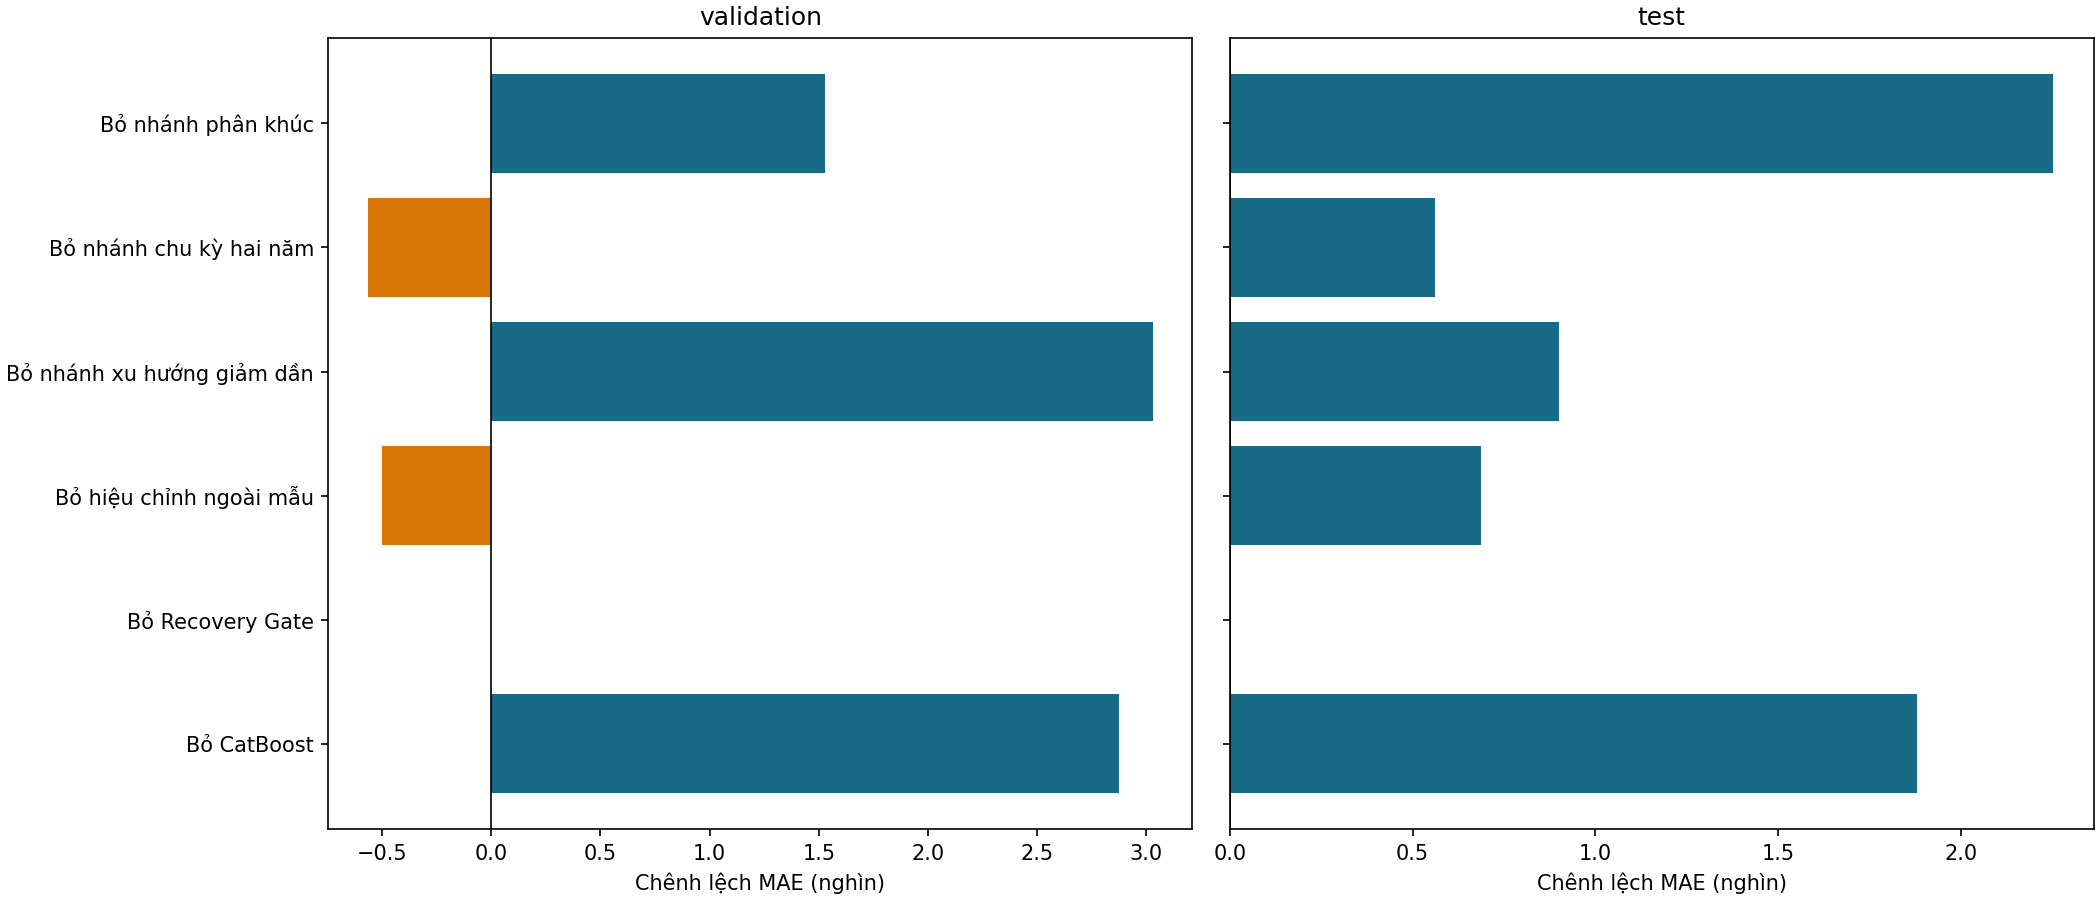

In [42]:
summary=abl_scores.groupby(['Split','Variant','Chỉ tiêu'])[['MAE','RMSE','R²']].mean()
for split in ['validation','test']:
    tab=summary.loc[split].unstack('Chỉ tiêu').reindex(variants)
    print(split.upper());display(tab.round(6))
    maes=tab['MAE'];delta=maes.subtract(maes.loc[FULL],axis=1)
    delta['MAE tổng hợp']=delta[targets].mean(axis=1)
    print('Chênh lệch MAE so với Hybrid đầy đủ (triệu)');display(delta.round(6))
print('MAE từng lượt validation (trung bình Revenue/COGS)')
display(abl_scores.loc[abl_scores.Split.eq('validation')].pivot_table(index='Variant',columns='Fold',values='MAE').reindex(variants).round(6))
fig,axes=plt.subplots(1,2,figsize=(14,6),layout='constrained',sharey=True)
for ax,split in zip(axes,['validation','test']):
    m=summary.loc[split]['MAE'].unstack('Chỉ tiêu').reindex(variants).mean(axis=1)
    delta=(m-m.loc[FULL]).iloc[1:]*1000
    ax.barh(delta.index,delta.values,color=['#176B87' if x>=0 else '#D97706' for x in delta]);ax.axvline(0,color='black',linewidth=.8);ax.set_title(split);ax.set_xlabel('Chênh lệch MAE (nghìn)')
with BytesIO() as buffer:
    fig.savefig(buffer, format="png", dpi=150)
    display(Image(data=buffer.getvalue(), width=950))
plt.close(fig)


### 8.4. Kết luận và giới hạn
**Kết quả thực nghiệm:** trên test, Hybrid đầy đủ đạt MAE tổng hợp khoảng 0,468741 triệu/ngày. Trong sáu phép loại bỏ, nhánh phân khúc có chênh lệch MAE lớn nhất (+0,002251 triệu); bỏ CatBoost (+0,001881), nhánh xu hướng giảm dần (+0,000900), chu kỳ hai năm (+0,000562) và hiệu chỉnh ngoài mẫu (+0,000686) cũng làm tăng MAE tổng hợp. Hiệu chỉnh ngoài mẫu có tác động trái chiều giữa Revenue và COGS. Recovery Gate không tạo khác biệt trong các mốc khảo sát, do điều kiện phát hiện suy giảm và kích hoạt phục hồi không đồng thời thỏa mãn. Trên validation, bỏ hiệu chỉnh ngoài mẫu hoặc nhánh chu kỳ hai năm giảm nhẹ MAE trung bình, nên không thể kết luận mọi thành phần đều hữu ích ở mọi giai đoạn.

Các mức chênh lệch là kết quả có điều kiện trên kiến trúc đã chốt, không cộng thành tổng đóng góp và không dùng để chọn lại mô hình theo nhãn test. Test là đánh giá hồi cứu, không độc lập hoàn toàn với quá trình nghiên cứu kiến trúc trước đây. Notebook này không thay đổi dữ liệu gốc hay dự báo chính.